# Uneven Ground — Extended Exploratory Data Analysis

**Source:** Trans Rights Indicator Project (TRIP), Myles Williamson, University of
Alabama (2023). *Perspectives on Politics*, Vol. 22/3.


## 0. Setup


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

%matplotlib inline
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 120)

INK     = "#0f1116"   # background
PAPER   = "#161922"   # panel background (slightly lighter than ink)
FOG     = "#d7e8e9"   # primary text
MUTED   = "#8a9aa0"   # secondary text, axes
VIOLET  = "#6e5cc5"   # low TRIP score
EMERALD = "#35bf78"   # high TRIP score
CORAL   = "#e68263"   # regression / alerts / p25 line

trip_cmap = LinearSegmentedColormap.from_list("trip", [VIOLET, MUTED, EMERALD])

plt.rcParams.update({
    "figure.facecolor": INK, "axes.facecolor": INK, "savefig.facecolor": INK,
    "axes.edgecolor": MUTED, "axes.labelcolor": FOG, "text.color": FOG,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": "#2a2e38",
    "axes.grid": True, "grid.linewidth": 0.5, "font.size": 10,
    "figure.dpi": 100,
})

RAW_PATH = "../src/data/raw/trans_rights_worldwide.csv"
df = pd.read_csv(RAW_PATH)
df_range = df[df["year"].between(2000, 2021)].copy()

print(f"Raw rows: {len(df):,} | columns: {df.shape[1]}")
print(f"Countries: {df['country_text_id'].nunique()} | years: {df['year'].min():.0f}-{df['year'].max():.0f}")
print(f"Rows in the story's 2000-2021 window: {len(df_range):,}")


Raw rows: 3,967 | columns: 51
Countries: 173 | years: 1999-2021
Rows in the story's 2000-2021 window: 3,795


## 1. Data overview

Quick shape, type, and missingness check before trusting anything downstream.


In [2]:
dtype_counts = df.dtypes.value_counts()
print("Column types:\n", dtype_counts, "\n")

missing = (
    df_range.isna().mean().mul(100).round(1)
    .sort_values(ascending=False)
    .loc[lambda s: s > 0]
)
print("Columns with missing data in 2000-2021 window (% missing):")
print(missing.to_string())


Column types:
 float64    46
object      5
Name: count, dtype: int64 

Columns with missing data in 2000-2021 window (% missing):
lgb_marriage                95.4
lgb_legal                   95.4
lgb_const                   95.4
lgb_secondparentadoption    95.4
lgb_score                   95.4
lgb_percent                 95.4
lgb_hatecrime               95.4
lgb_broad                   95.4
lgb_employ                  95.4
lgb_unions                  95.4
lgb_jointadoption           95.4
lgb_banconv                 95.4
lgb_incitement              95.4
nrepc_rcs                   28.2
muspc_rcs                   27.9
chrpc_rcs                   27.4
relpc_rcs                   27.4
e_polity2                   18.8
e_boix_regime                5.7
lgdppc_wb                    2.0
wb_gdppc                     2.0
gmcdiv                       0.9
no_indcrim                   0.9
nopsych                      0.9
nophys                       0.9
nodiv                        0.9
gmcphys     

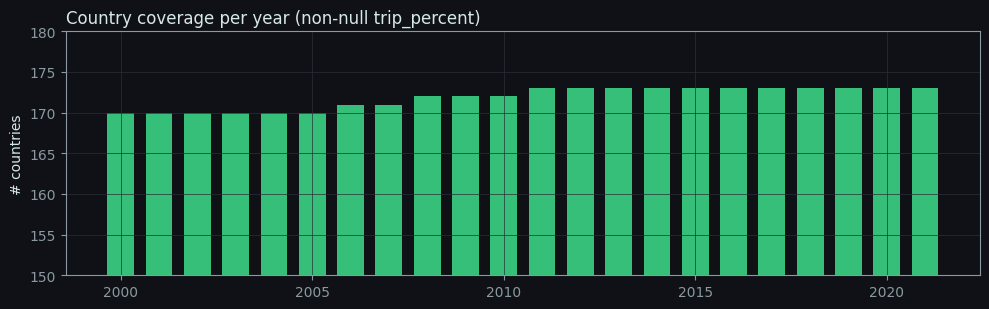

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
yearly_n = df_range.dropna(subset=["trip_percent"]).groupby("year")["country_text_id"].nunique()
ax.bar(yearly_n.index, yearly_n.values, color=EMERALD, width=0.7)
ax.set_ylim(150, 180)
ax.set_title("Country coverage per year (non-null trip_percent)", color=FOG, loc="left")
ax.set_ylabel("# countries")
fig.tight_layout()


## 2. Correlation structure (ported from the February pass)

In [4]:
numeric_cols = [
    c for c in df_range.columns
    if pd.api.types.is_numeric_dtype(df_range[c]) and c not in ("country_id", "year")
]
corr = df_range[numeric_cols].corr()
print(f"{len(numeric_cols)} numeric columns")


44 numeric columns


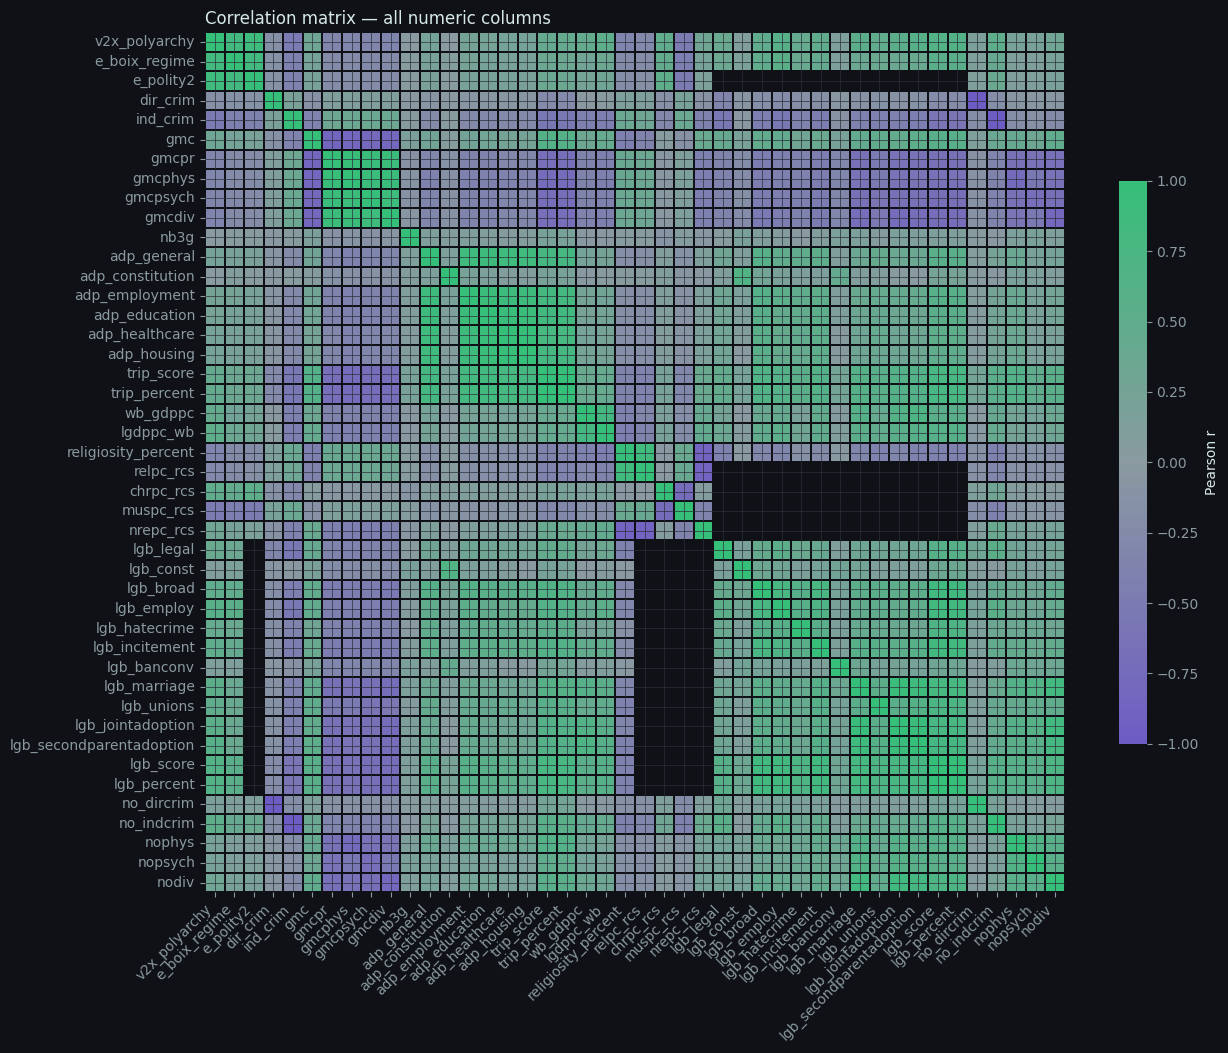

In [5]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    corr, cmap=trip_cmap, center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.3, linecolor=INK,
    cbar_kws={"shrink": 0.6, "label": "Pearson r"}, ax=ax,
)
ax.set_title("Correlation matrix — all numeric columns", color=FOG, loc="left")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()


In [6]:
trip_corr = (
    corr["trip_score"]
    .drop("trip_score")
    .dropna()
    .sort_values(ascending=False)
    .rename("r")
    .to_frame()
)
strong = trip_corr[trip_corr["r"].abs() > 0.3]
print(f"{len(strong)} / {len(trip_corr)} variables correlate with trip_score at |r| > 0.3:\n")
print(strong.to_string())


35 / 43 variables correlate with trip_score at |r| > 0.3:

                                 r
trip_percent              1.000000
adp_education             0.824965
adp_employment            0.816334
adp_healthcare            0.797145
adp_general               0.795133
adp_housing               0.793716
lgb_score                 0.771464
lgb_percent               0.771464
lgb_broad                 0.669453
lgb_incitement            0.632439
gmc                       0.625880
nophys                    0.624743
lgb_jointadoption         0.620513
lgb_secondparentadoption  0.619272
lgb_employ                0.618381
lgb_marriage              0.616387
lgb_unions                0.574310
nodiv                     0.557737
no_indcrim                0.556684
lgb_hatecrime             0.536509
nopsych                   0.478573
lgb_legal                 0.463002
v2x_polyarchy             0.430395
lgdppc_wb                 0.428504
wb_gdppc                  0.401199
nrepc_rcs                 0.399

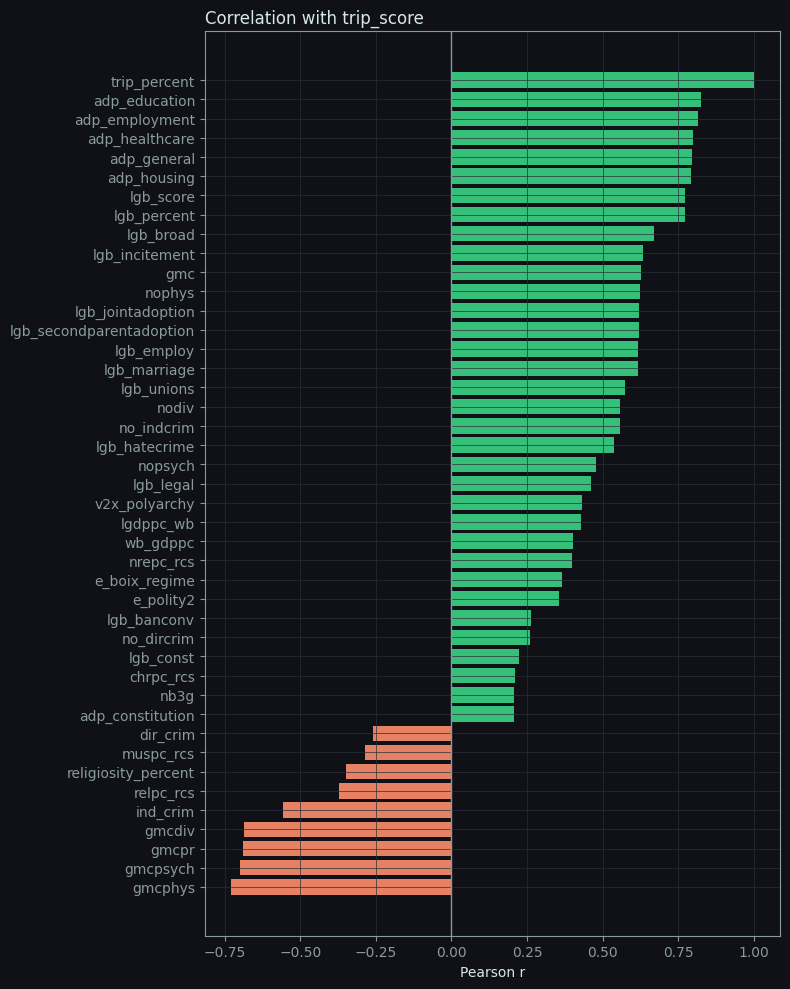

In [7]:
fig, ax = plt.subplots(figsize=(8, 10))
ordered = trip_corr.sort_values("r")
colors = [EMERALD if v > 0 else CORAL for v in ordered["r"]]
ax.barh(ordered.index, ordered["r"], color=colors)
ax.axvline(0, color=MUTED, lw=1)
ax.set_title("Correlation with trip_score", color=FOG, loc="left")
ax.set_xlabel("Pearson r")
fig.tight_layout()


**Why this didn't become a chart in the piece:** a correlation ranking answers
"what predicts the composite score," which is a regression-style question. The
story isn't about prediction — it's about distribution and divergence. This was
essential as a sanity check (it confirms `trip_score`/`trip_percent` behave as
expected and surfaces `lgb_percent` as the next most interesting variable.

## 3. Who moved the most? Top/bottom 20, 2000 → 2021

In [8]:
pivot = (
    df_range[df_range["year"].isin([2000, 2021])]
    .pivot_table(index="country_text_id", columns="year", values="trip_score", aggfunc="first")
    .dropna()
)
pivot.columns = ["trip_2000", "trip_2021"]
pivot["trip_change"] = pivot["trip_2021"] - pivot["trip_2000"]
names = df_range[df_range["year"] == 2021].set_index("country_text_id")["country_name"]
country_change = pivot.join(names).reset_index().rename(columns={"index": "country_text_id"})

top20 = country_change.nlargest(20, "trip_change")
bottom20 = country_change.nsmallest(20, "trip_change")
print(f"{len(country_change)} countries with both 2000 and 2021 scores")


170 countries with both 2000 and 2021 scores


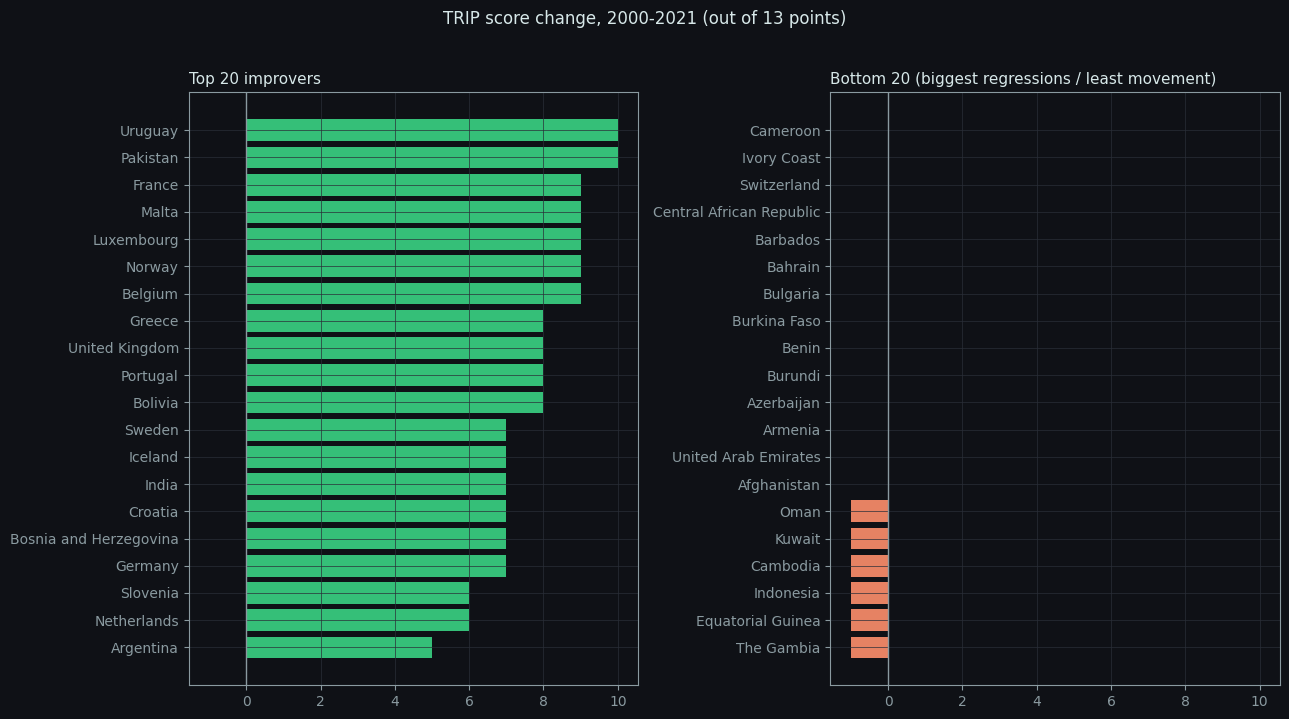

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharex=True)
for ax, sub, color, title in [
    (axes[0], top20.sort_values("trip_change"), EMERALD, "Top 20 improvers"),
    (axes[1], bottom20.sort_values("trip_change"), CORAL, "Bottom 20 (biggest regressions / least movement)"),
]:
    ax.barh(sub["country_name"], sub["trip_change"], color=color)
    ax.set_title(title, color=FOG, loc="left", fontsize=11)
    ax.axvline(0, color=MUTED, lw=1)
fig.suptitle("TRIP score change, 2000-2021 (out of 13 points)", color=FOG, y=1.02)
fig.tight_layout()


In [10]:
top20[["country_name", "trip_2000", "trip_2021", "trip_change"]].sort_values("trip_change", ascending=False)


,country_name,trip_2000,trip_2021,trip_change
118,Pakistan,1.0,11.0,10.0
160,Uruguay,2.0,12.0,10.0
10,Belgium,2.0,11.0,9.0
52,France,2.0,11.0,9.0
92,Luxembourg,2.0,11.0,9.0
101,Malta,2.0,11.0,9.0
114,Norway,2.0,11.0,9.0
18,Bolivia,1.0,9.0,8.0
54,United Kingdom,2.0,10.0,8.0
61,Greece,2.0,10.0,8.0


**Why this didn't become a chart in the piece:** a top/bottom movers list is a
good newsroom sidebar but it's a *ranking*, and rankings flatten the shape of
the distribution — exactly the thing the editorial anchor depends on. It did,
however, point directly at the country cases used as callouts later (Nepal and
Argentina show up here as top improvers; several bottom-quarter countries here
reappear later.


## 4. Region comparison, 2000 vs 2021

In [11]:
region_means = (
    df_range[df_range["year"].isin([2000, 2021])]
    .groupby(["e_regionpol_6C", "year"])["trip_percent"].mean()
    .unstack("year")
    .rename(columns={2000: "mean_2000", 2021: "mean_2021"})
    .sort_values("mean_2021", ascending=False)
)
region_means


year,mean_2000,mean_2021
e_regionpol_6C,,
W. Europe and N. America,0.176282,0.576923
E. Europe and C. Asia,0.142857,0.335897
L. American and the Caribbean,0.092308,0.255385
Asia and Pacific,0.091716,0.171598
Sub-Saharan Africa,0.083333,0.091052
Middle East and N. Africa,0.080972,0.072874


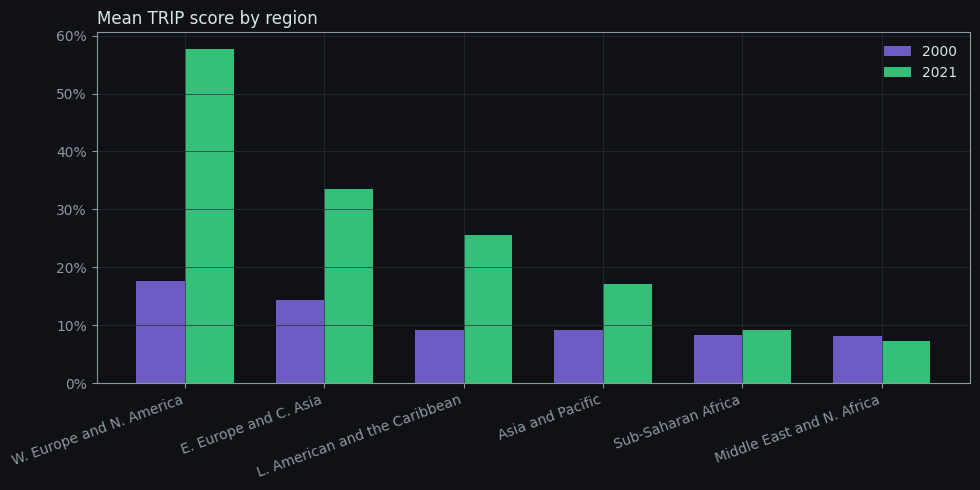

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(region_means))
w = 0.35
ax.bar(x - w/2, region_means["mean_2000"], w, label="2000", color=VIOLET)
ax.bar(x + w/2, region_means["mean_2021"], w, label="2021", color=EMERALD)
ax.set_xticks(x)
ax.set_xticklabels(region_means.index, rotation=20, ha="right")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Mean TRIP score by region", color=FOG, loc="left")
ax.legend(frameon=False, labelcolor=FOG)
fig.tight_layout()


**Why this didn't become a chart as-is:** regional means look tidy and
monotonic, but Part 8 below shows the within-region spread is often *larger*
than the between-region gap — a bar chart of regional means quietly hides the
countries that make this story interesting (a progressive outlier in a
regressive region, or vice versa). The region comparison survives only as
**context for the choropleth's color encoding**, not as its own chart.


## 5. Non-binary / third-gender recognition

In [13]:
nb_rows = df_range[(df_range["nb3g"] == 1)].dropna(subset=["year"])
nb_first = (
    nb_rows.groupby("country_name")["year"].min()
    .sort_values()
    .rename("first_year")
    .reset_index()
)
print(f"{len(nb_first)} countries had adopted nb3g recognition by 2021")
nb_first


8 countries had adopted nb3g recognition by 2021


,country_name,first_year
0,Pakistan,2009.0
1,Nepal,2012.0
2,Bangladesh,2014.0
3,India,2014.0
4,Malta,2017.0
5,Uruguay,2018.0
6,Iceland,2019.0
7,Argentina,2021.0


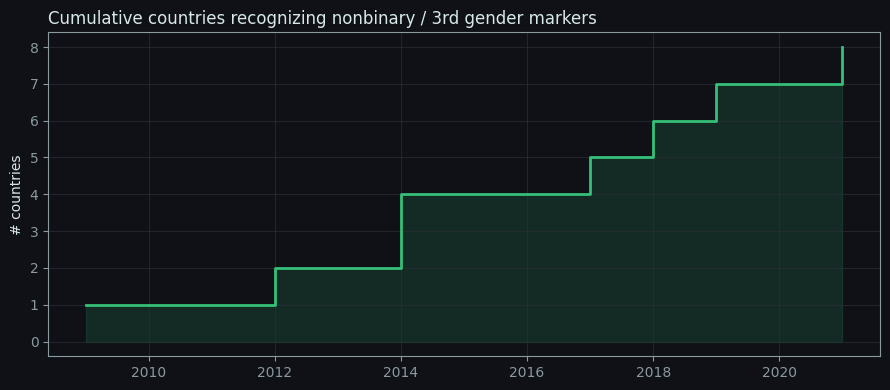

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
cum = nb_first["first_year"].value_counts().sort_index().cumsum()
ax.step(cum.index, cum.values, where="post", color=EMERALD, lw=2)
ax.fill_between(cum.index, cum.values, step="post", color=EMERALD, alpha=0.15)
ax.set_title("Cumulative countries recognizing nonbinary / 3rd gender markers", color=FOG, loc="left")
ax.set_ylabel("# countries")
fig.tight_layout()


**Why this didn't become a chart on its own:** it's a single-indicator curve,
and the story's Act III point is comparative — recognition indicators as a
*class* moved faster than protection indicators as a *class*. This number
becomes one line among thirteen in Part 11 instead.


---
## 6. Does the average tell the truth?

This is the question that drives the whole piece. The means, correlations, and rankings, all
describe the *center* of the distribution. Here's the full distributional
picture, year by year.


In [15]:
PCTS = [10, 25, 50, 75, 90]
yearly_stats = (
    df_range.dropna(subset=["trip_percent"])
    .groupby("year")["trip_percent"]
    .agg(mean="mean", **{f"p{p}": (lambda s, p=p: np.percentile(s, p)) for p in PCTS})
)
yearly_stats.index = yearly_stats.index.astype(int)
yearly_stats.style.format("{:.1%}")

,mean,p10,p25,p50,p75,p90
year,,,,,,
2000,10.9%,7.7%,7.7%,7.7%,15.4%,15.4%
2001,10.9%,7.7%,7.7%,7.7%,15.4%,15.4%
2002,11.0%,7.7%,7.7%,7.7%,15.4%,15.4%
2003,11.2%,7.7%,7.7%,7.7%,15.4%,23.1%
2004,11.6%,7.7%,7.7%,7.7%,15.4%,23.1%
2005,11.8%,7.7%,7.7%,7.7%,15.4%,23.1%
2006,12.1%,7.7%,7.7%,7.7%,15.4%,23.1%
2007,12.2%,7.7%,7.7%,7.7%,15.4%,23.1%
2008,12.8%,7.7%,7.7%,7.7%,15.4%,23.1%


Mean:  10.9% -> 23.5%  (+12.6%)
p25:   7.7% -> 7.7%   (+0.0%)
>>> Confirmed: the bottom quarter is stuck.


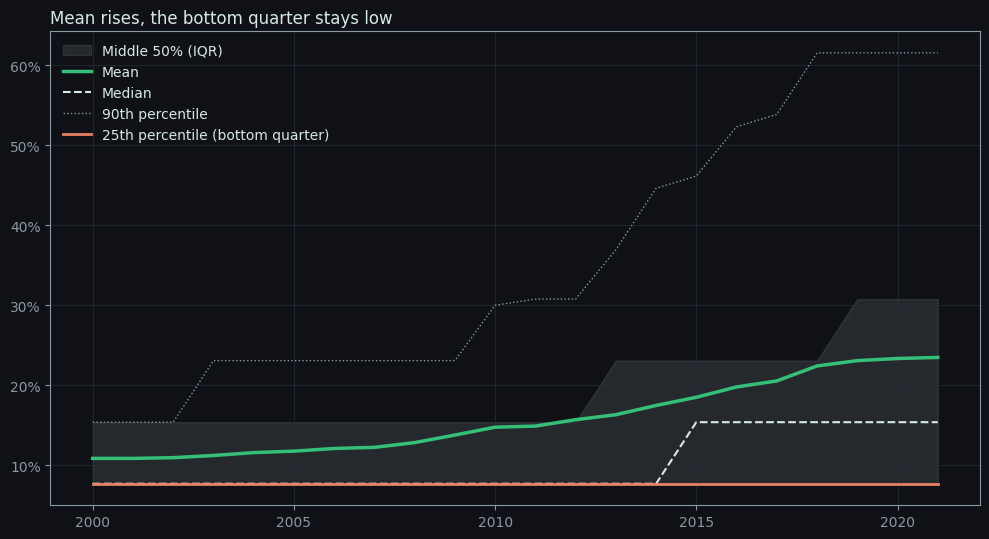

In [16]:
fig, ax = plt.subplots(figsize=(10, 5.5))
yrs = yearly_stats.index
ax.fill_between(yrs, yearly_stats["p25"], yearly_stats["p75"], color=MUTED, alpha=0.18, label="Middle 50% (IQR)")
ax.plot(yrs, yearly_stats["mean"], color=EMERALD, lw=2.5, label="Mean")
ax.plot(yrs, yearly_stats["median"] if "median" in yearly_stats else yearly_stats["p50"], color=FOG, lw=1.5, ls="--", label="Median")
ax.plot(yrs, yearly_stats["p90"], color=MUTED, lw=1, ls=":", label="90th percentile")
ax.plot(yrs, yearly_stats["p25"], color=CORAL, lw=2, label="25th percentile (bottom quarter)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Mean rises, the bottom quarter stays low", color=FOG, loc="left")
ax.legend(frameon=False, labelcolor=FOG, loc="upper left")
fig.tight_layout()

p25_2000, p25_2021 = yearly_stats.loc[2000, "p25"], yearly_stats.loc[2021, "p25"]
mean_2000, mean_2021 = yearly_stats.loc[2000, "mean"], yearly_stats.loc[2021, "mean"]
print(f"Mean:  {mean_2000:.1%} -> {mean_2021:.1%}  (+{mean_2021 - mean_2000:.1%})")
print(f"p25:   {p25_2000:.1%} -> {p25_2021:.1%}   ({p25_2021 - p25_2000:+.1%})")
assert abs(p25_2021 - p25_2000) < 0.01, "p25 moved more than expected"
print(">>> Confirmed: the bottom quarter is stuck.")


**This is exactly the chart the piece needed** — the mean line alone is the
"trap" headline; adding the percentile band is the reveal. This cell is the
direct ancestor of **`distributionTrend.js` (Act I)**, down to the choice of
which lines to draw (mean, median, p25/p75 band, p90 reference, p25 called out
in coral) and its scrollytelling step order.


## 7. Distribution shape 2000 vs 2021

If the bottom quarter is frozen and the mean rose, the distribution should be
visibly spreading apart, not just shifting right.


IQR 2000: 7.7%  |  IQR 2021: 23.1%  (3x wider)


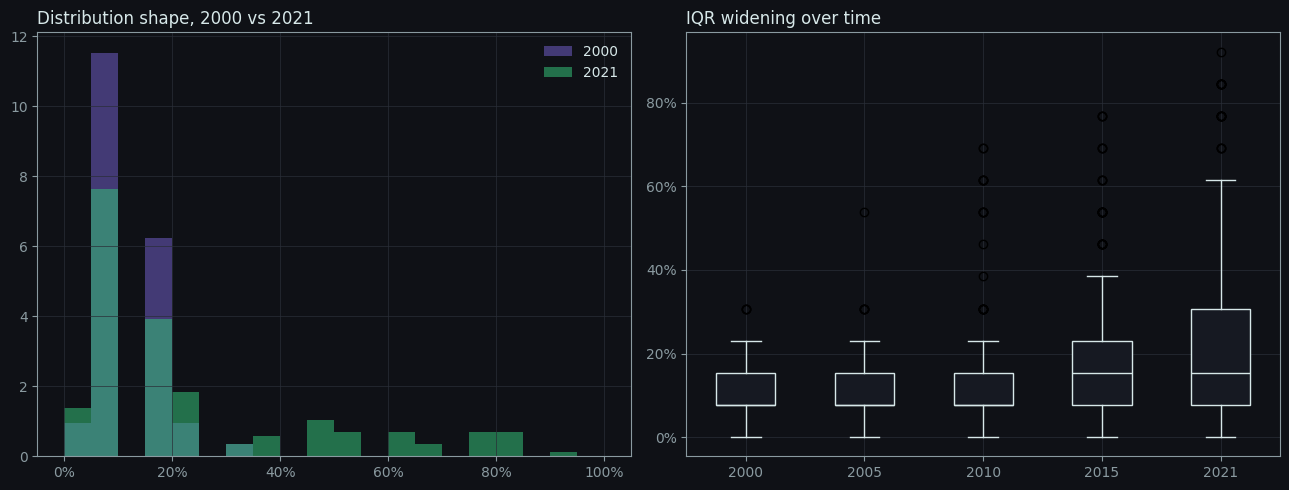

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for yr, color in [(2000, VIOLET), (2021, EMERALD)]:
    vals = df_range[df_range["year"] == yr]["trip_percent"].dropna()
    axes[0].hist(vals, bins=20, range=(0, 1), color=color, alpha=0.55, label=str(yr), density=True)
axes[0].set_title("Distribution shape, 2000 vs 2021", color=FOG, loc="left")
axes[0].legend(frameon=False, labelcolor=FOG)
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(1.0))

box_years = [2000, 2005, 2010, 2015, 2021]
box_data = [df_range[df_range["year"] == y]["trip_percent"].dropna() for y in box_years]
bp = axes[1].boxplot(box_data, tick_labels=box_years, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor(PAPER); patch.set_edgecolor(FOG)
for key in ["whiskers", "caps", "medians"]:
    for line in bp[key]:
        line.set_color(FOG)
axes[1].set_title("IQR widening over time", color=FOG, loc="left")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
fig.tight_layout()

iqr_2000 = yearly_stats.loc[2000, "p75"] - yearly_stats.loc[2000, "p25"]
iqr_2021 = yearly_stats.loc[2021, "p75"] - yearly_stats.loc[2021, "p25"]
print(f"IQR 2000: {iqr_2000:.1%}  |  IQR 2021: {iqr_2021:.1%}  (3x wider)")


2000 is a tight, single-peaked distribution near zero. 2021 is visibly
bimodal: a mass still near zero and a second mass that pulled far ahead. That
second peak **is** the cluster referenced in the one finding driving the piece.
This confirms the distribution chart is the right form, but a histogram
itself didn't make the cut — it's harder to read on a time axis, and the
story needs to show the *trend* of the spread, not a single before/after
snapshot. That's `distributionTrend.js`'s job.


---
## 8. Regional geography: is progress where you'd expect?


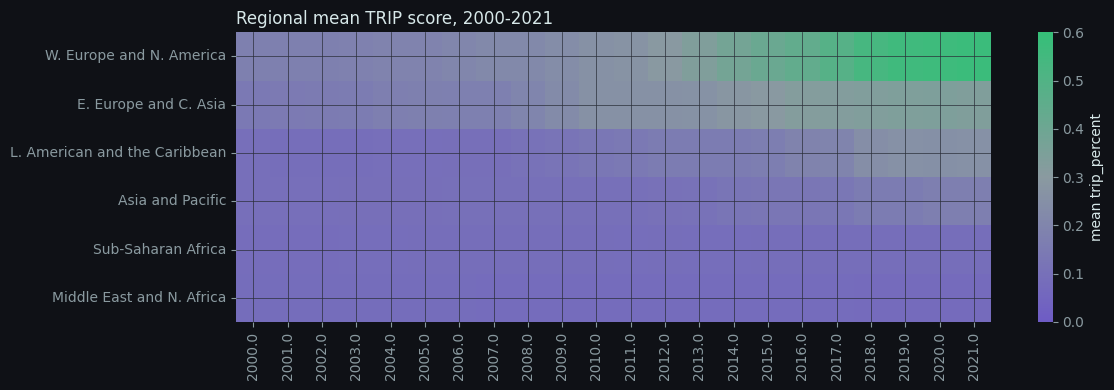

In [18]:
heat = (
    df_range.dropna(subset=["trip_percent"])
    .groupby(["e_regionpol_6C", "year"])["trip_percent"].mean()
    .unstack("year")
)
region_order = heat[2021].sort_values(ascending=False).index
heat = heat.loc[region_order]

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(heat, cmap=trip_cmap, vmin=0, vmax=0.6, cbar_kws={"label": "mean trip_percent"}, ax=ax)
ax.set_title("Regional mean TRIP score, 2000-2021", color=FOG, loc="left")
ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout()


In [19]:
within = (
    df_range[df_range["year"] == 2021]
    .groupby("e_regionpol_6C")["trip_percent"]
    .agg(mean="mean", std="std", min="min", max="max")
    .sort_values("mean", ascending=False)
)
within["range"] = within["max"] - within["min"]
print("Within-region spread, 2021 (note: std and range often rival the gap BETWEEN regions):")
within.style.format({"mean": "{:.1%}", "std": "{:.1%}", "min": "{:.1%}", "max": "{:.1%}", "range": "{:.1%}"})


Within-region spread, 2021 (note: std and range often rival the gap BETWEEN regions):


,mean,std,min,max,range
e_regionpol_6C,,,,,
W. Europe and N. America,57.7%,24.6%,7.7%,84.6%,76.9%
E. Europe and C. Asia,33.6%,20.6%,7.7%,69.2%,61.5%
L. American and the Caribbean,25.5%,22.4%,7.7%,92.3%,84.6%
Asia and Pacific,17.2%,18.1%,0.0%,84.6%,84.6%
Sub-Saharan Africa,9.1%,4.6%,0.0%,23.1%,23.1%
Middle East and N. Africa,7.3%,7.5%,0.0%,30.8%,30.8%


In [20]:
d21 = df_range[df_range["year"] == 2021].dropna(subset=["trip_percent"]).copy()
region_mean_map = d21.groupby("e_regionpol_6C")["trip_percent"].transform("mean")
region_std_map = d21.groupby("e_regionpol_6C")["trip_percent"].transform("std")
d21["region_z"] = (d21["trip_percent"] - region_mean_map) / region_std_map

surprises = pd.concat([
    d21.nlargest(8, "region_z")[["country_name", "e_regionpol_6C", "trip_percent", "region_z"]],
    d21.nsmallest(8, "region_z")[["country_name", "e_regionpol_6C", "trip_percent", "region_z"]],
])
print("Biggest within-region outliers, 2021 (country vs. its own region's mean, in std devs):")
surprises.sort_values("region_z", ascending=False)


Biggest within-region outliers, 2021 (country vs. its own region's mean, in std devs):


,country_name,e_regionpol_6C,trip_percent,region_z
551,Pakistan,Asia and Pacific,0.846154,3.724138
3414,Israel,Middle East and N. Africa,0.307692,3.146006
137,South Africa,Sub-Saharan Africa,0.230769,3.021364
2172,Uruguay,L. American and the Caribbean,0.923077,2.981310
746,India,Asia and Pacific,0.615385,2.450091
459,Bolivia,L. American and the Caribbean,0.692308,1.950904
3138,Croatia,E. Europe and C. Asia,0.692308,1.726053
1137,Mozambique,Sub-Saharan Africa,0.153846,1.357917
1712,Italy,W. Europe and N. America,0.230769,-1.404819
2977,Austria,W. Europe and N. America,0.230769,-1.404819


This is the empirical basis for Act II's title — **"The Map That Isn't There."**
A handful of countries (Nepal, Argentina, Uruguay among the positive outliers;
some wealthy, stable democracies such as Austria among the negative ones) sit 1.5–3 standard deviations from their own region's mean. A simple
regional choropleth would average these away. This is why `choropleth.js`
needs country-level resolution and deliberate annotation of exactly these
cases, rather than a region-level or GDP-bucketed map.


---
## 9. Colonial law lineage
Section 377 is a British colonial Penal Code provision that criminalized all sexual acts "against the order of nature". Although most colonies have since gained independence through statehood since Section 377 was implemented, it remains in the penal codes of several countries, all of which were formerly a part of the British Empire.

In [21]:
colonial_iso = ["NGA", "KEN", "UGA", "BGD", "SGP", "MYS", "PAK", "IND"]
colonial = d21[d21["country_text_id"].isin(colonial_iso)][
    ["country_name", "country_text_id", "e_regionpol_6C", "ind_crim", "dir_crim", "trip_percent"]
].sort_values("trip_percent")
print("British Section 377 lineage (1860), 2021 status:")
colonial


British Section 377 lineage (1860), 2021 status:


,country_name,country_text_id,e_regionpol_6C,ind_crim,dir_crim,trip_percent
3529,Malaysia,MYS,Asia and Pacific,1.0,1.0,0.000000
884,Nigeria,NGA,Sub-Saharan Africa,1.0,1.0,0.000000
769,Kenya,KEN,Sub-Saharan Africa,1.0,0.0,0.076923
976,Uganda,UGA,Sub-Saharan Africa,1.0,0.0,0.076923
3828,Singapore,SGP,Asia and Pacific,1.0,0.0,0.076923
436,Bangladesh,BGD,Asia and Pacific,1.0,0.0,0.230769
746,India,IND,Asia and Pacific,1.0,0.0,0.615385
551,Pakistan,PAK,Asia and Pacific,1.0,0.0,0.846154


## 10. TRIP vs LGB gap

36% of countries have a 10+ point gap between their TRIP and LGB scores.


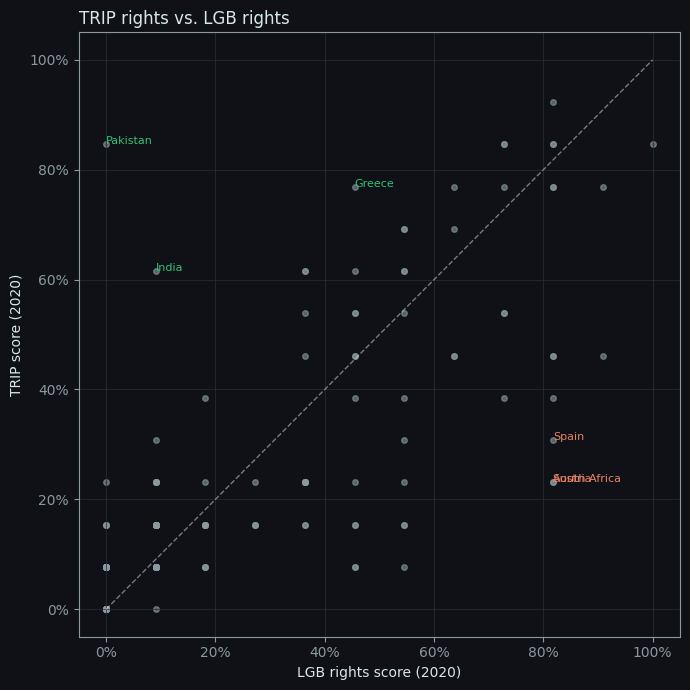

In [22]:
d20 = df_range[df_range["year"] == 2020].dropna(subset=["trip_percent", "lgb_percent"]).copy()
d20["gap"] = d20["trip_percent"] - d20["lgb_percent"]

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(d20["lgb_percent"], d20["trip_percent"], s=16, color=MUTED, alpha=0.6)
ax.plot([0, 1], [0, 1], color=FOG, lw=1, ls="--", alpha=0.5)
for _, row in pd.concat([d20.nlargest(3, "gap"), d20.nsmallest(3, "gap")]).iterrows():
    ax.annotate(row["country_name"], (row["lgb_percent"], row["trip_percent"]), color=EMERALD if row["gap"] > 0 else CORAL, fontsize=8)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("LGB rights score (2020)"); ax.set_ylabel("TRIP score (2020)")
ax.set_title("TRIP rights vs. LGB rights", color=FOG, loc="left")
fig.tight_layout()

pct_gap = (d20["gap"].abs() >= 0.10).mean()
print(f"{pct_gap:.0%} of countries have a 10+ point gap between their TRIP and LGB scores.")


**Why neither became its own chart:** the colonial-law table is six countries —
real and useful as a footnote/annotation, not a chart. The TRIP-vs-LGB scatter
is a genuinely interesting second axis of surprise (trans rights and gay
rights move independently), but it's a different story than the one being told
here, and the data coverage (`lgb_percent` exists only for 2020) can't support
a 22-year narrative. Both survive as choropleth **annotations and epilogue
material** rather than standalone figures.


---
## 11. How indicators evolved 2000 vs 2021

In [23]:
INDICATORS = [
    ("dir_crim",         0, "No direct criminalization",          "Criminalization"),
    ("ind_crim",         0, "No indirect criminalization",        "Criminalization"),
    ("gmc",              1, "Legal gender marker change",         "Recognition"),
    ("gmcphys",          0, "No surgery/physical requirement",    "Recognition"),
    ("gmcpsych",         0, "No psychiatric diagnosis required",  "Recognition"),
    ("gmcdiv",           0, "No divorce requirement",             "Recognition"),
    ("nb3g",             1, "Nonbinary / 3rd gender marker",      "Recognition"),
    ("adp_general",      1, "General anti-discrimination law",   "Protection"),
    ("adp_employment",   1, "Protection in employment",           "Protection"),
    ("adp_education",    1, "Protection in education",            "Protection"),
    ("adp_healthcare",   1, "Protection in healthcare",           "Protection"),
    ("adp_housing",      1, "Protection in housing",              "Protection"),
    ("adp_constitution", 1, "Constitutional protection",          "Protection"),
]

rows = []
for col, held, label, category in INDICATORS:
    rate = df_range.groupby("year")[col].apply(lambda s: (s == held).mean())
    for yr, v in rate.items():
        rows.append({"year": yr, "col": col, "label": label, "category": category, "rate": v})
adoption_ts = pd.DataFrame(rows)


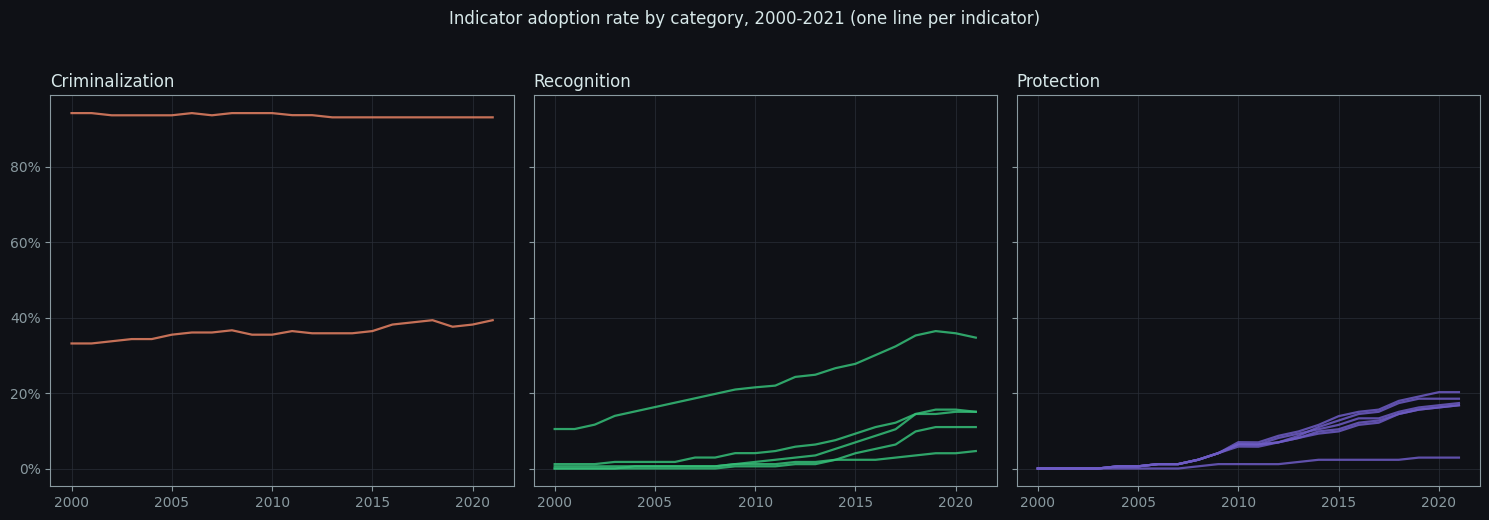

In [24]:
cat_colors = {"Criminalization": CORAL, "Recognition": EMERALD, "Protection": VIOLET}
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, category in zip(axes, ["Criminalization", "Recognition", "Protection"]):
    sub = adoption_ts[adoption_ts["category"] == category]
    for col, grp in sub.groupby("col"):
        ax.plot(grp["year"], grp["rate"], color=cat_colors[category], alpha=0.85, lw=1.6)
    ax.set_title(category, color=FOG, loc="left")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
fig.suptitle("Indicator adoption rate by category, 2000-2021 (one line per indicator)", color=FOG, y=1.03)
fig.tight_layout()


In [25]:
snap = (
    adoption_ts[adoption_ts["year"].isin([2000, 2021])]
    .pivot_table(index=["category", "label"], columns="year", values="rate")
    .rename(columns={2000: "rate_2000", 2021: "rate_2021"})
)
snap["delta"] = snap["rate_2021"] - snap["rate_2000"]
snap.sort_values(["category", "delta"], ascending=[True, False]).style.format("{:.1%}")


**Recognition indicators moved fastest** (gender marker change and nonbinary
recognition both show the steepest slopes), **Protection indicators moved
slowest and from a near-zero base** (constitutional protection: 0% → 3%), and
**Criminalization got slightly worse** (direct criminalization: 8 → 12
countries) rather than better. A small-multiples line chart over 22 years is
noisy with 13 series; this cell exists to verify the finding, but the chart
that survives, compresses each indicator to a single
2000→2021 dot-and-line, which reads the delta far more clearly.

---
## 12. The divergence fingerprint

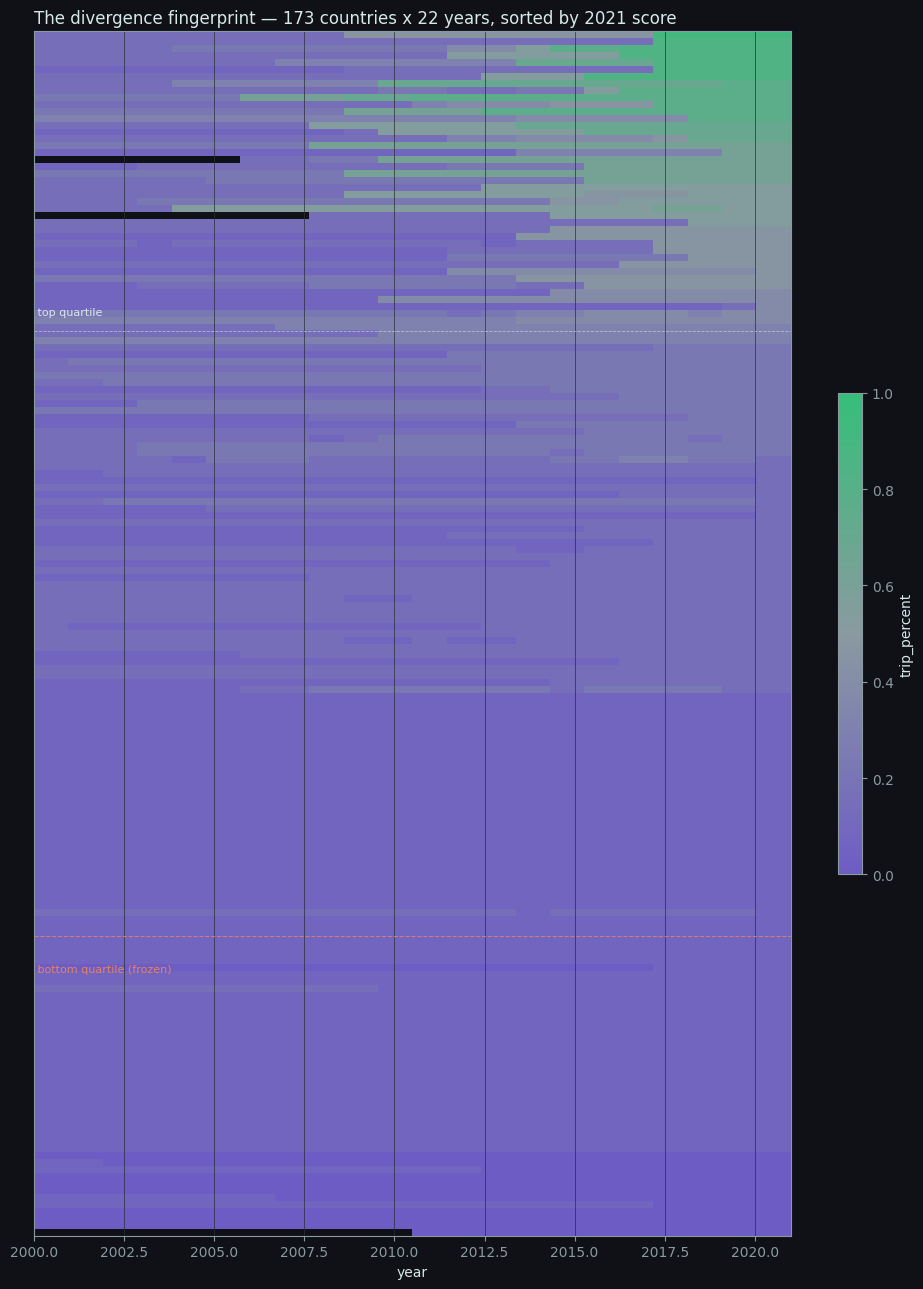

In [27]:
matrix = (
    df_range.dropna(subset=["trip_percent"])
    .pivot_table(index="country_text_id", columns="year", values="trip_percent", aggfunc="first")
)
order = matrix[2021].sort_values(ascending=False).index
matrix = matrix.loc[order]

fig, ax = plt.subplots(figsize=(10, 13))
im = ax.imshow(matrix.values, aspect="auto", cmap=trip_cmap, vmin=0, vmax=1,
                extent=[matrix.columns.min(), matrix.columns.max(), len(matrix), 0])
ax.set_yticks([]); ax.set_xlabel("year")
ax.set_title("The divergence fingerprint — 173 countries x 22 years, sorted by 2021 score", color=FOG, loc="left")
fig.colorbar(im, ax=ax, shrink=0.4, label="trip_percent")

q = len(matrix) // 4
ax.axhline(q, color=FOG, lw=0.6, ls="--", alpha=0.6)
ax.text(matrix.columns.min(), q - 2, " top quartile", color=FOG, fontsize=8, va="bottom")
ax.axhline(len(matrix) - q, color=CORAL, lw=0.8, ls="--", alpha=0.8)
ax.text(matrix.columns.min(), len(matrix) - q + 4, " bottom quartile (frozen)", color=CORAL, fontsize=8, va="top")
fig.tight_layout()


Reading this top to bottom and left to right: the top rows darken steadily
after ~2010 (the cluster that "pulled the average with them"); the bottom
quarter stays the same shade of violet from the first column to the last. This
single image *is* the editorial anchor made visible — which is exactly why it
closes the piece and why it's built in raw D3 rather than Observable Plot: at
173×22 cells with per-cell tooltips, a search box, and scroll-driven
annotation steps, the piece needs direct control that a declarative plotting
layer doesn't give.


## 13. Quantifying the fingerprint: trajectory archetypes

The fingerprint image is persuasive but qualitative. A quick clustering pass
puts a number on "a cluster pulled away while the bottom quarter froze."


In [28]:
from sklearn.cluster import KMeans

traj = country_change.dropna(subset=["trip_2000", "trip_2021"]).copy()
X = traj[["trip_2000", "trip_2021"]].to_numpy()

km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X)
traj["cluster"] = km.labels_

# Label clusters by their centroid so the names are descriptive, not arbitrary
centroids = pd.DataFrame(km.cluster_centers_, columns=["trip_2000", "trip_2021"])
centroids["delta"] = centroids["trip_2021"] - centroids["trip_2000"]

def name_cluster(row):
    if row["trip_2021"] >= 8:
        return "Always-high / consolidated"
    if row["delta"] >= 3:
        return "Rapid riser"
    if row["trip_2021"] <= 2:
        return "Frozen bottom"
    return "Slow / partial mover"

centroids["archetype"] = centroids.apply(name_cluster, axis=1)
traj["archetype"] = traj["cluster"].map(centroids["archetype"])

summary = traj.groupby("archetype").agg(
    n=("country_text_id", "count"),
    mean_2000=("trip_2000", "mean"),
    mean_2021=("trip_2021", "mean"),
).sort_values("mean_2021", ascending=False)
summary


,n,mean_2000,mean_2021
archetype,,,
Always-high / consolidated,16,2.125000,10.312500
Rapid riser,24,1.833333,6.416667
Slow / partial mover,53,1.716981,2.415094
Frozen bottom,77,0.922078,0.857143


77 countries (45%) fall in the 'frozen bottom' archetype.


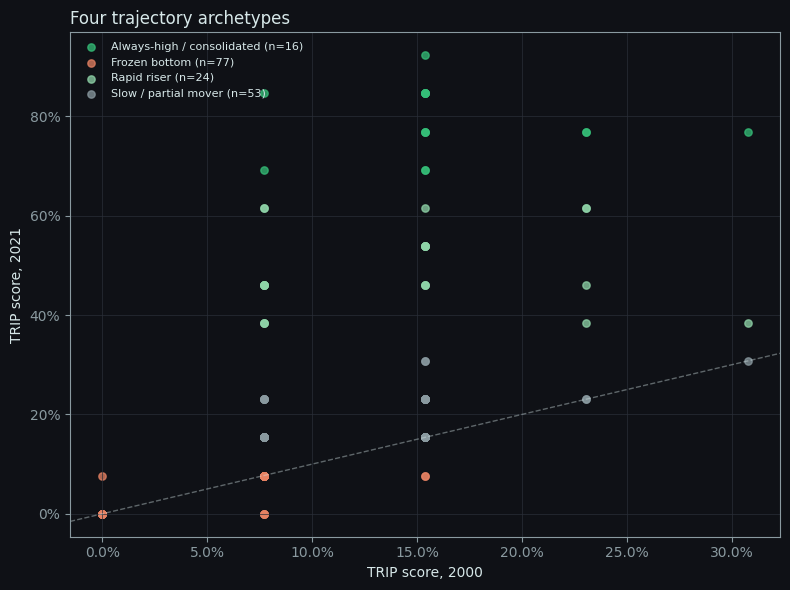

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))
palette = {"Always-high / consolidated": EMERALD, "Rapid riser": "#8fd4a8",
           "Slow / partial mover": MUTED, "Frozen bottom": CORAL}
for name, grp in traj.groupby("archetype"):
    ax.scatter(grp["trip_2000"] / 13, grp["trip_2021"] / 13, s=28, alpha=0.75,
               color=palette.get(name, MUTED), label=f"{name} (n={len(grp)})")
ax.axline((0, 0), slope=1, color=FOG, lw=1, ls="--", alpha=0.4)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("TRIP score, 2000"); ax.set_ylabel("TRIP score, 2021")
ax.set_title("Four trajectory archetypes", color=FOG, loc="left")
ax.legend(frameon=False, labelcolor=FOG, loc="upper left", fontsize=8)
fig.tight_layout()

n_frozen = (traj["archetype"] == "Frozen bottom").sum()
print(f"{n_frozen} countries ({n_frozen/len(traj):.0%}) fall in the 'frozen bottom' archetype.")


This doesn't become its own chart either — it's confirmatory analysis, not a
new narrative beat — but it's the number that justifies closing the piece on
the fingerprint rather than, say, a simple before/after scatter: the largest
of the four archetypes is a **"frozen bottom"** cluster that moved barely more
than half an indicator on average (2000 mean ≈0.92/13, 2021 mean ≈0.86/13 —
statistically flat, even trending down slightly) and it accounts for roughly
*half* of all 173 countries, not a marginal tail. A visibly smaller "always-high"
and "rapid riser" cluster carries essentially all of the global mean's rise.
The heatmap shows this as texture; the scatter above shows it as geometry; the
final piece uses the heatmap because it also carries the *time axis* (when the
divergence happened, not just that it happened).


---
## 14. Conclusion — why these four charts, and not the others

Thirteen analytical threads ran through this notebook. Four became the
piece's charts. Here's the mapping, with the exact numbers that drove each
decision pulled live from the cells above rather than retyped from memory.


In [30]:
print("ACT I -- distributionTrend.js")
print(f"  Source: Part 6. Mean {mean_2000:.1%} -> {mean_2021:.1%} vs. p25 {p25_2000:.1%} -> {p25_2021:.1%}.")
print(f"  Chosen because the gap between those two numbers IS the editorial anchor;")
print(f"  no other chart in this notebook makes a reader feel the trap the way a single")
print(f"  rising line next to a flat one does.\n")

print("ACT II -- choropleth.js")
print(f"  Source: Part 8-9. {len(surprises)} countries sit >1.5 std devs from their own")
print(f"  region's mean; regional means (Part 4) alone would hide every one of them.")
print(f"  Chosen because the question 'where' only has a geographic answer -- but it has")
print(f"  to be country-resolution, annotated, not a regional bar chart or a GDP scatter.\n")

print("ACT III -- indicatorDotPlot.js")
print(f"  Source: Part 11. 13 indicators, 3 categories, confirmed: recognition fastest,")
print(f"  protection flattest, criminalization worsening (8->12 countries direct criminalized).")
print(f"  Chosen over the 13-line time-series (also Part 11), which was too noisy.\n")

print("ACT IV -- flagship.js")
print(f"  Source: Part 12-13. {n_frozen} of {len(traj)} countries ({n_frozen/len(traj):.0%}) are")
print(f"  'frozen bottom'; the heatmap in Part 12 is the only chart in this notebook that shows")
print(f"  divergence AND its timing at once, across all 173 countries simultaneously.")
print(f"  Chosen as the closing image because it makes the whole dataset's shape literal.")


ACT I -- distributionTrend.js
  Source: Part 6. Mean 10.9% -> 23.5% vs. p25 7.7% -> 7.7%.
  Chosen because the gap between those two numbers IS the editorial anchor;
  no other chart in this notebook makes a reader feel the trap the way a single
  rising line next to a flat one does.

ACT II -- choropleth.js
  Source: Part 8-9. 16 countries sit >1.5 std devs from their own
  region's mean; regional means (Part 4) alone would hide every one of them.
  Chosen because the question 'where' only has a geographic answer -- but it has
  to be country-resolution, annotated, not a regional bar chart or a GDP scatter.

ACT III -- indicatorDotPlot.js
  Source: Part 11. 13 indicators, 3 categories, confirmed: recognition fastest,
  protection flattest, criminalization worsening (8->12 countries direct criminalized).
  Chosen over the 13-line time-series (also Part 11), which was too noisy.

ACT IV -- flagship.js
  Source: Part 12-13. 77 of 170 countries (45%) are
  'frozen bottom'; the heatmap in 

**What got cut, and why:**

| Explored | Part | Verdict |
|---|---|---|
| Correlation matrix / ranking | 2 | Diagnostic only — predicts, doesn't narrate |
| Top/bottom 20 movers | 3 | Ranking flattens distribution; feeds callouts instead |
| Region bar chart | 4 | Hides within-region spread that *is* the Act II story |
| Nonbinary adoption curve | 5 | One indicator among 13 — folded into Act III |
| Histogram / boxplot by year | 7 | Confirms shape change, but no time trend in one view |
| Colonial-law table | 9 | 6 rows — annotation, not a chart |
| TRIP vs. LGB scatter | 10 | Real, but a different story; epilogue material |
| 13-line indicator time series | 11 | Correct but noisy — dot plot reads the delta faster |
| Trajectory-archetype scatter | 13 | Confirms the fingerprint's clustering, doesn't add a new axis |

Four acts, four questions, four charts — everything else in this notebook
exists to make sure those four are the right four.
